torch.Size([2, 256, 256])


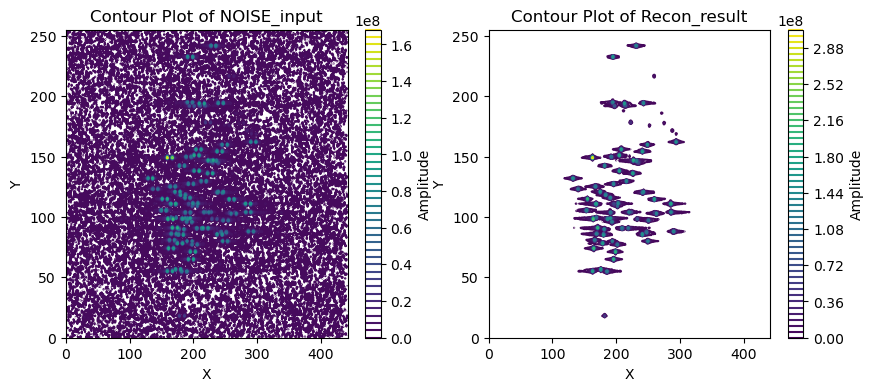

In [1]:
import scipy.io as scio
import matplotlib.pyplot as plt
import numpy as np
import torch

def pad_data(data, block_size):
    height, width = data.shape
    pad_height = (block_size - height % block_size) % block_size
    pad_width = (block_size - width % block_size) % block_size
    padded_data = np.pad(data, ((0, pad_height), (0, pad_width)), mode='constant', constant_values=0)
    return padded_data, pad_height, pad_width


def block_data(data, block_size):
    padded_data, pad_height, pad_width = pad_data(data, block_size)
    height, width = padded_data.shape
    num_blocks_vertical = height // block_size
    num_blocks_horizontal = width // block_size
    blocks = np.empty((num_blocks_vertical * num_blocks_horizontal, block_size, block_size), dtype=padded_data.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = padded_data[i*block_size:(i+1)*block_size, j*block_size:(j+1)*block_size]
            blocks[idx] = block
            idx += 1
    return blocks, padded_data.shape, pad_height, pad_width


def reconstruct_data(blocks, pad_shape, pad_height, pad_width):
    height, width = pad_shape
    num_blocks, block_height, block_width = blocks.shape
    num_blocks_vertical = height // block_height
    num_blocks_horizontal = width // block_width
    reconstructed_data = np.empty((height, width), dtype=blocks.dtype)
    idx = 0
    for i in range(num_blocks_vertical):
        for j in range(num_blocks_horizontal):
            block = blocks[idx]
            reconstructed_data[i*block_height:(i+1)*block_height, j*block_width:(j+1)*block_width] = block
            idx += 1
    final_data = reconstructed_data[:height if not pad_height else -pad_height, :width if not pad_width else -pad_width]
    return final_data


data = scio.loadmat('data/CON_Decouple.mat')
input_spec = data["IPAP"]
label_spec = data['decouple']

fig = plt.figure(2, figsize=(10, 4))
contour_levels = 50
ax = fig.add_subplot(121)
contour_input = ax.contour(np.abs(input_spec), levels=contour_levels, cmap='viridis')
ax.set_title('Contour Plot of NOISE_input')
ax.set_xlabel('X')
ax.set_ylabel('Y')
plt.colorbar(contour_input, ax=ax, label='Amplitude')
ax = fig.add_subplot(122)
contour_input = ax.contour(np.abs(label_spec), levels=contour_levels, cmap='viridis')
ax.set_title('Contour Plot of Recon_result')
ax.set_xlabel('X')
ax.set_ylabel('Y')
plt.colorbar(contour_input, ax=ax, label='Amplitude')

NOISE_input = input_spec
NUS_FID = np.fft.ifft(input_spec, axis=-1)

input_size = 256
phase_input, pad_shape, pad_height, pad_width = block_data(NUS_FID, input_size)

NUS_FID, _, _, _ = block_data(NUS_FID, input_size)
NOISE_input, _, _, _ = block_data(NOISE_input, input_size)

GT_label = label_spec
GT_label, _, _, _ = block_data(GT_label, input_size)
block_num = phase_input.shape[0]

max_amp = np.max(np.abs(NOISE_input)) * 2
NUS_FID = torch.complex(torch.from_numpy(NUS_FID.real).float(), torch.from_numpy(NUS_FID.imag).float()) / (max_amp)
NOISE_input = torch.complex(torch.from_numpy(NOISE_input.real).float(), torch.from_numpy(NOISE_input.imag).float()) / (max_amp)
GT_label = torch.complex(torch.from_numpy(GT_label.real).float(), torch.from_numpy(GT_label.imag).float()) / (max_amp)

LR = NUS_FID.unsqueeze(1)
SR = torch.cat((NOISE_input.real.unsqueeze(1), NOISE_input.imag.unsqueeze(1)), dim=1)
HR = torch.cat((GT_label.real.unsqueeze(1), GT_label.imag.unsqueeze(1)), dim=1)
print(GT_label.shape)
val_data = {'LR': LR, 'HR': HR, 'SR': SR}


In [2]:
import os
import torch
import logging
import random
import numpy as np
import scipy.io as scio
from tqdm import tqdm
from torch.utils.data import Dataset
import data as Data
import model as Model
import argparse
import logging
import core.logger as Logger
import core.metrics as Metrics
import os
from data import dataset
import matplotlib.pyplot as plt

parser = argparse.ArgumentParser()
parser.add_argument('-c', '--config', type=str, default='config/sr_sr3_256_256_val.json',
                    help='JSON file for configuration')
parser.add_argument('-p', '--phase', type=str, choices=['train', 'val'], 
                    help='Run either train(training) or val(generation)', default='val')
parser.add_argument('-gpu', '--gpu_ids', type=str, default=None)
parser.add_argument('-debug', '-d', action='store_true')
parser.add_argument('-enable_wandb', action='store_true')
parser.add_argument('-log_wandb_ckpt', action='store_true')
parser.add_argument('-log_eval', action='store_true')

args =parser.parse_known_args()[0]
opt = Logger.parse(args)
opt = Logger.dict_to_nonedict(opt)

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True
Logger.setup_logger(None, opt['path']['log'],
                    'train', level=logging.INFO, screen=True)
Logger.setup_logger('val', opt['path']['log'], 'val', level=logging.INFO)
logger = logging.getLogger('base')
logger.info(Logger.dict2str(opt))

diffusion = Model.create_model(opt)
logger.info('Initial Model Finished')

current_step = diffusion.begin_step
current_epoch = diffusion.begin_epoch
n_iter = opt['train']['n_iter']

if opt['path']['resume_state']:
    logger.info('Resuming training from epoch: {}, iter: {}.'.format(
        current_epoch, current_step))
diffusion.set_new_noise_schedule(
    opt['model']['beta_schedule'][opt['phase']], schedule_phase=opt['phase'])

export CUDA_VISIBLE_DEVICES=1


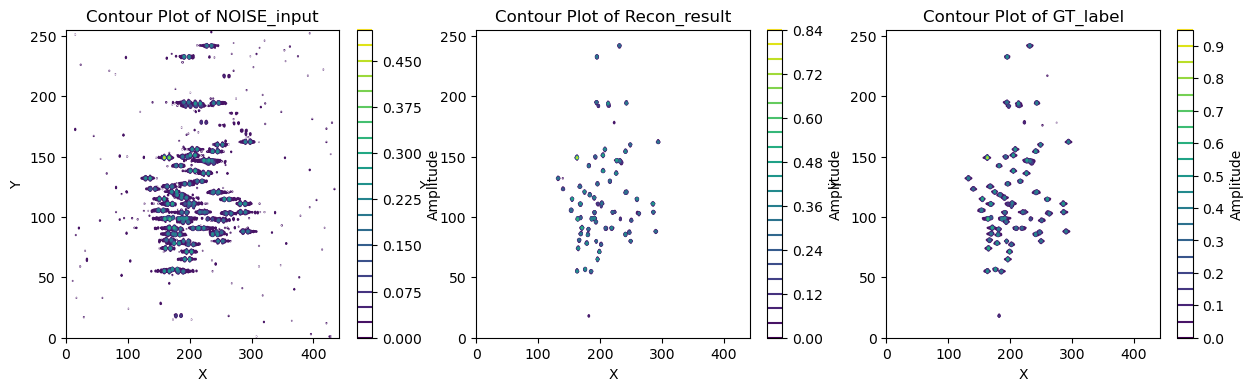

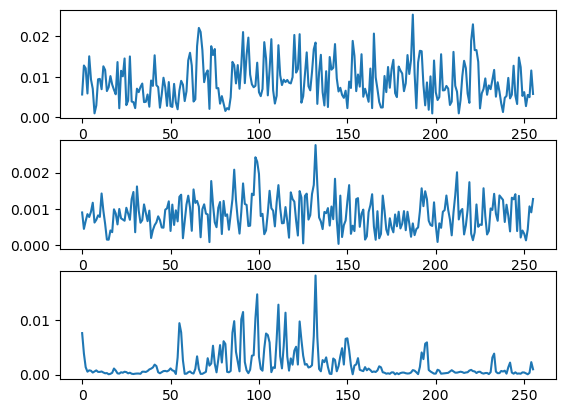

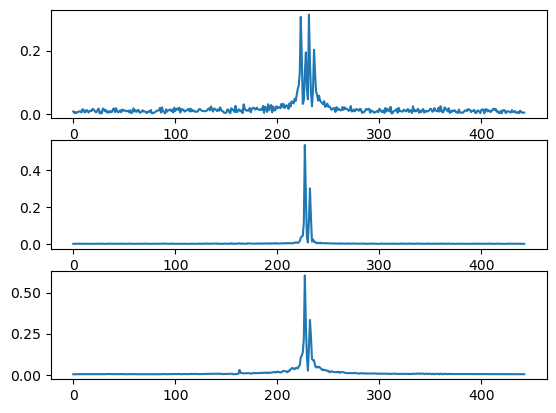

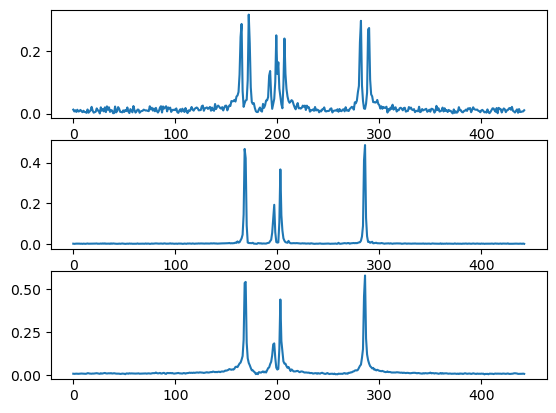

In [3]:
avg_mse = 0.0
result_path = '{}/{}'.format(opt['path']['results'], 100)
os.makedirs(result_path, exist_ok=True)
diffusion.set_new_noise_schedule(opt['model']['beta_schedule']['val'], schedule_phase='val')

val_data = diffusion.set_device(val_data)
diffusion.feed_data(val_data)
diffusion.test(continous=False, pnp_mode='vd')
visuals = diffusion.get_current_visuals()

try:
    if block_num is not None:
        fake_img = reconstruct_data(torch.complex(visuals['INF'][0 : block_num , 0], visuals['INF'][0 : block_num , 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        sr_img = reconstruct_data(torch.complex(visuals['SR'][-block_num : , 0], visuals['SR'][-block_num :, 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        hr_img = reconstruct_data(torch.complex(visuals['HR'][0 : block_num , 0], visuals['HR'][0 : block_num , 1]).cpu().numpy(), pad_shape, pad_height, pad_width)
        lr_img = reconstruct_data(visuals['LR'][0 : block_num].squeeze(1).cpu().numpy(), pad_shape, pad_height, pad_width)

except NameError:
    fake_img = torch.complex(visuals['INF'][0, 0], visuals['INF'][0, 1]).squeeze().cpu().numpy()
    sr_img = torch.complex(visuals['SR'][-1, 0], visuals['SR'][-1, 1]).squeeze().cpu().numpy()
    hr_img = torch.complex(visuals['HR'][0, 0], visuals['HR'][0, 1]).squeeze().cpu().numpy()
    lr_img = visuals['LR'][0].squeeze().float().cpu().numpy()

Metrics.plot_contour(
        nus_spec=fake_img,
        recon_spec=sr_img,
        label_spec=hr_img,
        fig_num=1)

fig = plt.figure(55)
ax = fig.add_subplot(311)
ax.plot(np.abs(fake_img[:, 120]))
ax = fig.add_subplot(312)
ax.plot(np.abs(sr_img[:, 120]))
ax = fig.add_subplot(313)
ax.plot(np.abs(hr_img[:, 120]))

fig = plt.figure(66)
ax = fig.add_subplot(311)
ax.plot(np.abs(fake_img[147, :]))
ax = fig.add_subplot(312)
ax.plot(np.abs(sr_img[147, :]))
ax = fig.add_subplot(313)
ax.plot(np.abs(hr_img[147, :]))

fig = plt.figure(77)
ax = fig.add_subplot(311)
ax.plot(np.abs(fake_img[111, :]))
ax = fig.add_subplot(312)
ax.plot(np.abs(sr_img[111, :]))
ax = fig.add_subplot(313)
ax.plot(np.abs(hr_img[111, :]))
